In [40]:
from torch.utils.data import Dataset
import pandas as pd
from pathlib import Path
from PIL import Image
import torch
import numpy as np
from torch.utils.data import DataLoader
from torchvision.transforms.functional import to_tensor
from sklearn.model_selection import train_test_split
import random

In [2]:
ROOT_PATH = "data/faces_webface_112x112"

In [3]:
df = pd.read_csv(f"{ROOT_PATH}/train.csv")

### Split Train Val

In [4]:
df_train, df_val = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"],
)

In [5]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [6]:
print("Train:")
print(df_train["label"].value_counts(normalize=True))

print("\nValidation:")
print(df_val["label"].value_counts(normalize=True))

Train:
label
819     0.001633
3410    0.001516
138     0.001447
1321    0.001327
3384    0.001320
          ...   
9804    0.000010
759     0.000010
4328    0.000008
4383    0.000008
9282    0.000005
Name: proportion, Length: 10572, dtype: float64

Validation:
label
819     0.001641
3410    0.001518
138     0.001447
1321    0.001325
3384    0.001325
          ...   
9782    0.000010
759     0.000010
1148    0.000010
3748    0.000010
8269    0.000010
Name: proportion, Length: 10571, dtype: float64


In [7]:
print("Train:")
print(df_train["label"].value_counts())

print("\nValidation:")
print(df_val["label"].value_counts())

Train:
label
819     641
3410    595
138     568
1321    521
3384    518
       ... 
9804      4
759       4
4328      3
4383      3
9282      2
Name: count, Length: 10572, dtype: int64

Validation:
label
819     161
3410    149
138     142
1321    130
3384    130
       ... 
9782      1
759       1
1148      1
3748      1
8269      1
Name: count, Length: 10571, dtype: int64


In [8]:
labels_train = set(df_train["label"].unique())
labels_val = set(df_val["label"].unique())

print("Labels missing from validation:", labels_train - labels_val)
print("Labels missing from training:", labels_val - labels_train)

Labels missing from validation: {np.int64(9282)}
Labels missing from training: set()


In [9]:
print("Training length before:", len(df_train))
df_train = df_train[df_train["label"] != 9282].reset_index(drop=True)
print("Training length after:", len(df_train))

Training length before: 392498
Training length after: 392496


### Dataset

In [10]:
def preprocess_input(image):
    image /= 255.0 
    image -= 0.5
    image /= 0.5
    return image

In [11]:
def resize_image(image, size, letterbox_image):
    iw, ih  = image.size
    w, h    = size
    if letterbox_image:
        scale   = min(w/iw, h/ih)
        nw      = int(iw*scale)
        nh      = int(ih*scale)

        image   = image.resize((nw,nh), Image.BICUBIC)
        new_image = Image.new('RGB', size, (128,128,128))
        new_image.paste(image, ((w-nw)//2, (h-nh)//2))
    else:
        new_image = image.resize((w, h), Image.BICUBIC)
    return new_image

In [54]:
class LabeledFaceDataset(Dataset):
    def __init__(self, df, split="train", width=112, height=112):
        self.df = df
        self.split = split
        self.width = width
        self.height = height 

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        root_path = Path(ROOT_PATH)
        
        image_path = root_path / row["path"].lstrip("/")
        image = Image.open(image_path).convert("RGB")
        label = int(row["label"])
        
        if self.split == "train" and random.random() < 0.5:
            image = image.transpose(Image.FLIP_LEFT_RIGHT)
            
        image = resize_image(image, [self.width, self.height], letterbox_image = True)
        arr_image = np.transpose(preprocess_input(np.array(image, dtype='float32')), (2, 0, 1))
        
        return image, arr_image, label

In [55]:
train_dataset = LabeledFaceDataset(df=df_train, split="train")

In [56]:
image, arr_image, label = train_dataset[0]

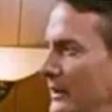

In [58]:
image

In [59]:
label

2883

In [63]:
arr_image.shape, arr_image.min(), arr_image.max()

((3, 112, 112), np.float32(-1.0), np.float32(1.0))

In [64]:
val_dataset = LabeledFaceDataset(df=df_val, split="val")

In [65]:
image, arr_image, label = val_dataset[0]

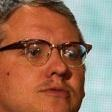

In [66]:
image

In [67]:
label

3623

In [68]:
arr_image.shape, arr_image.min(), arr_image.max()

((3, 112, 112), np.float32(-1.0), np.float32(1.0))

### Data Loader

In [72]:
batch_size = 32
num_workers = 1

In [78]:
def dataset_collate(batch):
    images  = []
    targets = []
    for _, image, y in batch:
        images.append(image)
        targets.append(y)
    images  = torch.from_numpy(np.array(images)).type(torch.FloatTensor)
    targets = torch.from_numpy(np.array(targets)).long()
    return images, targets

In [79]:
train_loader = DataLoader(
    train_dataset, 
    shuffle=False, 
    batch_size=batch_size, 
    num_workers=num_workers, 
    pin_memory=True,
    collate_fn=dataset_collate, 
)

In [80]:
images, labels = next(iter(train_loader))

In [81]:
images.shape

torch.Size([32, 3, 112, 112])

In [82]:
labels.shape

torch.Size([32])

In [83]:
labels

tensor([ 2883,  6924,  3384,  5526,  2667,   815,  5742,  5448,  1759,  6332,
          521,  7890,  2309,  9491,  2935,  2552,  8941,  7835,  6113,  6811,
         8496,  7030,  3847,  4040,  2404, 10287,  4693,  3478,  9524,  1244,
         9257,  6673])

In [89]:
val_loader = DataLoader(
    val_dataset, 
    shuffle=False, 
    batch_size=batch_size, 
    num_workers=num_workers, 
    pin_memory=True,
    collate_fn=dataset_collate, 
)

In [90]:
images, labels = next(iter(val_loader))

In [91]:
images.shape

torch.Size([32, 3, 112, 112])

In [92]:
labels.shape

torch.Size([32])

In [93]:
labels

tensor([3623, 4290, 2000, 8295, 7739, 2527, 4636, 3118, 9962, 6157, 1935, 5452,
        1810, 6697, 4730, 4603,  693, 4609, 2786,  453, 6425, 8263, 1529, 1005,
        2133, 1666,  404,  476, 7389, 9224, 7389,  290])

In [94]:
len(train_loader), len(val_loader)

(12266, 3067)

### Reverse

In [96]:
images[0].shape

torch.Size([3, 112, 112])

In [98]:
def reverse_preprocess_input(image):
    image = (image * 0.5 + 0.5) * 255.0
    image = image.clamp(0, 255).byte()
    image = image.permute(1, 2, 0).cpu().numpy()
    return Image.fromarray(image)

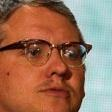

In [99]:
reverse_preprocess_input(images[0])